In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

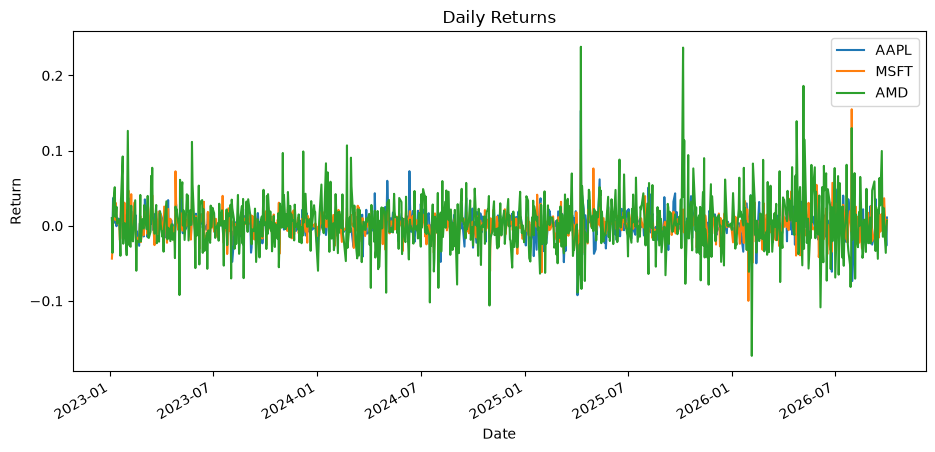

In [16]:
#q1 I used gemini ONLY to figure out how to download the data. I couldn't find it on the nasdaq.com site (it wouldn't let me download) so I had gemini figure out the links to where to download.For q8 i used SPY because that was the best I could find for S&P 500

start="2023-01-03"
end="2026-09-30"#dates so i don't have to keep typing it out every single time

def file_load(filename):
    df=pd.read_csv(filename)
    df["Date"]=pd.to_datetime(df["Date"])
    close=df["Close/Last"].astype(str).str.replace(r"[\$,]","",regex=True).astype(float) #why did they use this as column name idk, it seems kinda weird to add the /Last. got an error without the regex=True. that is new to me
    s=pd.Series(close.values,index=df["Date"])
    return s.sort_index().loc[start:end]

prices=pd.DataFrame({"AAPL":file_load("AAPL.csv"),"MSFT":file_load("MSFT.csv"),"AMD":file_load("AMD.csv")})
returns=prices.pct_change().dropna()
returns.plot(figsize=(11,5))
plt.title("Daily Returns")
plt.ylabel("Return")
plt.show()

#the nasdaq.com prices appear to not be dividend adjusted but they are split-adjusted.(split=change in stock volume)


In [17]:
#q2
annual_avg=252*returns.mean()
annual_std=np.sqrt(252)*returns.std()
print(pd.DataFrame({"Mean":annual_avg,"Std Dev": annual_std}))

          Mean   Std Dev
AAPL  0.296343  0.258112
MSFT  0.238897  0.263350
AMD   0.765228  0.567480


In [18]:
#q3
print(returns.cov()*252)#https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.cov.html
print(returns.corr())#https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-corr/

          AAPL      MSFT       AMD
AAPL  0.066622  0.025717  0.043166
MSFT  0.025717  0.069353  0.052224
AMD   0.043166  0.052224  0.322034
          AAPL      MSFT       AMD
AAPL  1.000000  0.378342  0.294702
MSFT  0.378342  1.000000  0.349448
AMD   0.294702  0.349448  1.000000


In [ ]:
#q4
m=annual_avg.values
sig=(252*returns.cov()).values
n=list(returns.columns)
stds=np.sqrt(np.diag(sig))#https://www.geeksforgeeks.org/python/numpy-diag-python/

#class 19 to 21 had alot, so im reusing it. 
def global_min_variance_portfolio(Sigma):
    n = Sigma.shape[0]
    Sigma_inv = np.linalg.inv(Sigma)#comp inverse
    ones = np.ones(n)  #vectors of 1s have length n
    w_gmv = Sigma_inv @ ones
    w_gmv /= np.sum(w_gmv)
    return w_gmv


def min_var_portfolio(r, Sigma, target_return):
    n = len(r) #total asset num from legnth of expected
    mu = np.array(r)
    Sigma = np.array(Sigma)
    Sigma_inv = np.linalg.inv(Sigma)
    A = mu @ Sigma_inv @ mu#scalar const
    B = mu @ Sigma_inv @ np.ones(n)
    C = np.ones(n) @ Sigma_inv @ np.ones(n)
    D = A * C - B**2
    lambda1 = (C * target_return - B) / D
    lambda2 = (A - B * target_return) / D
    w = Sigma_inv @ (lambda1 * mu + lambda2 * np.ones(n))
    return w

